# 04 · Rolling effects: do promotions carry over to the next days, and do promotions at other stores matter?

Builds on `03_linear_regression_wz.ipynb` (same two outcomes: roll takings and total shop takings, same controls including list price and month).
Two additions:

1. **Rolling (lagged) effects.** For each horizon `k` = 1, 2, 3 we predict takings on day **n+k** from what was running on day **n** (`promotion`, `other_promotion`).
   `k` = 0 is the same-day model from 03, for comparison.
2. **Promotion at other stores.** `promo_elsewhere` = 1 if *another* store is running a roll `promotion` that day (0 otherwise).
   It captures spill-over between stores, e.g. customers moving to the store with the deal.
   The `other_promotion` column is the same at all three stores on every date, so its "elsewhere" version would just duplicate the store's own value and is left out.

**Why each model also controls for what is running on day n+k.** Promotions last 1-2 weeks, so a promotion on day n is usually *still running* on day n+k.
Without that control the lag coefficient would just re-measure the same-day effect. With it, the lag coefficient answers:
*"given what is running today, does having had the promotion k days ago change takings?"* (a hangover dip or a lingering boost).
Section 5 shows the difference.

How to read a coefficient: £ per store-day versus no promotion; the reference group is Kingston Park, Monday, January, no promotion.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titlesize": 10, "axes.titleweight": "bold",
})
BLUE = "#2a78d6"

df = pd.read_csv("../data/clean.csv", parse_dates=["date"]).sort_values(["store_id", "date"]).reset_index(drop=True)

## 1. Build the variables

`list_price` and `month` are built as in 03. `promo_elsewhere` counts the stores running a roll promotion on that date, minus the store itself.
(None of the rows dropped in `00_data_cleaning` were promotion days, so the counts are complete.)

In [2]:
price = (df.sausage_roll_takings_gbp / df.sausage_rolls_sold).round(2)
df["list_price"] = df.date.map(price[df.promotion == "none"].groupby(df.date).median())
df["month"] = df.date.dt.month

on = df.promotion != "none"
df["promo_elsewhere"] = ((on.groupby(df.date).transform("sum") - on) > 0).astype(int)

assert df.list_price.notna().all()
assert (df.groupby("date").other_promotion.nunique() == 1).all()  # other_promotion is identical across stores

pd.crosstab(df.promotion != "none", df.promo_elsewhere, rownames=["own promotion"], colnames=["promotion at another store"])

promotion at another store,0,1
own promotion,,
False,1866,209
True,105,0


## 2. Lagged data

For horizon `k`, each store-day (the outcome day, n+k) is joined to what was running at the **same store** `k` days earlier (`*_lag` columns).
Days where the earlier day is missing (the first `k` days, or a day dropped in cleaning) are lost, so each horizon has slightly fewer rows.

In [3]:
LAGGED = ["promotion", "other_promotion", "promo_elsewhere"]

def with_lag(k):
    earlier = df[["store_id", "date"] + LAGGED].assign(date=lambda x: x.date + pd.Timedelta(days=k))
    return df.merge(earlier, on=["store_id", "date"], suffixes=("", "_lag"))

data = {k: df if k == 0 else with_lag(k) for k in range(4)}
pd.Series({f"k={k}": len(d) for k, d in data.items()}, name="rows")

k=0    2180
k=1    2168
k=2    2165
k=3    2162
Name: rows, dtype: int64

## 3. Fit the models

Eight regressions: 2 outcomes x 4 horizons (`k` = 0 is the same day).

In [4]:
controls = ("C(store_id) + C(day_of_week, Treatment('Monday')) + temperature_c + rain + rain_mm"
            " + home_match_day + school_holidays + list_price + C(month, Treatment(1))")
running = "C(promotion, Treatment('none')) + C(other_promotion, Treatment('none')) + promo_elsewhere"        # on the outcome day
earlier = "C(promotion_lag, Treatment('none')) + C(other_promotion_lag, Treatment('none')) + promo_elsewhere_lag"  # k days before
outcomes = {"roll takings": "sausage_roll_takings_gbp", "shop takings": "total_shop_takings_gbp"}

fits = {}
for k, d in data.items():
    rhs = controls + " + " + running + ("" if k == 0 else " + " + earlier)
    for name, y in outcomes.items():
        fits[(name, k)] = smf.ols(f"{y} ~ {rhs}", data=d).fit()

pd.DataFrame({f"{name}, k={k}": {"rows": int(m.nobs), "R-squared": m.rsquared} for (name, k), m in fits.items()})

,"roll takings, k=0","shop takings, k=0","roll takings, k=1","shop takings, k=1","roll takings, k=2","shop takings, k=2","roll takings, k=3","shop takings, k=3"
rows,"2,180.000","2,180.000","2,168.000","2,168.000","2,165.000","2,165.000","2,162.000","2,162.000"
R-squared,0.440,0.463,0.442,0.464,0.441,0.464,0.441,0.464


## 4. Results

One row per variable. The `same day` column is the effect on the day itself (k = 0, as in 03 plus `promo_elsewhere`).
The `n+1`, `n+2`, `n+3` columns are the **carry-over** effect of having had that promotion 1, 2 or 3 days earlier, beyond what is running that day.
Cells show `coefficient (p-value)` in £.

In [5]:
def label(term):
    term = re.sub(r"C\((\w+),.*\)\[T\.(.*)\]", r"\1: \2", term)  # "C(promotion_lag, ...)[T.two_for_2]" -> "promotion_lag: two_for_2"
    return term.replace("_lag", "")

rows = []
for (name, k), m in fits.items():
    t = pd.concat([m.params, m.conf_int(), m.pvalues], axis=1)
    t.columns = ["coef", "low", "high", "p"]
    t = t[t.index.str.contains("promo") & (t.index.str.contains("_lag") == (k > 0))]  # k=0: same-day terms; k>0: the lagged terms
    rows.append(t.assign(outcome=name, k=k, variable=t.index.map(label)))
coefs = pd.concat(rows, ignore_index=True)

order = list(coefs[(coefs.outcome == "roll takings") & (coefs.k == 0)].variable)
horizon = {0: "same day", 1: "n+1", 2: "n+2", 3: "n+3"}

def results_table(outcome):
    c = coefs[coefs.outcome == outcome]
    text = c.coef.map("{:+.1f}".format) + " (p=" + c.p.map("{:.3f}".format) + ")"
    return c.assign(text=text).pivot(index="variable", columns="k", values="text").loc[order].rename(columns=horizon)

for name in outcomes:
    print(name)
    display(results_table(name))

roll takings


k,same day,n+1,n+2,n+3
variable,,,,
promotion: 20_percent_off,+17.4 (p=0.000),-1.5 (p=0.879),-2.6 (p=0.721),-2.1 (p=0.727)
promotion: one_pound_week,+46.0 (p=0.000),-19.1 (p=0.059),-15.6 (p=0.037),-7.0 (p=0.276)
promotion: two_for_2,+64.4 (p=0.000),-9.0 (p=0.368),-8.7 (p=0.228),-4.4 (p=0.463)
other_promotion: breakfast_bundle,+10.5 (p=0.003),-5.3 (p=0.599),-3.3 (p=0.654),-5.1 (p=0.410)
other_promotion: coffee_rewards_bonus,+13.1 (p=0.000),-4.0 (p=0.695),-1.6 (p=0.825),+1.6 (p=0.795)
other_promotion: hot_drink_bundle,+12.4 (p=0.003),+2.0 (p=0.844),+6.5 (p=0.373),+0.2 (p=0.970)
other_promotion: summer_lunch_deal,-5.3 (p=0.165),-0.6 (p=0.954),-1.3 (p=0.853),-2.3 (p=0.695)
other_promotion: sweet_treat_offer,-2.0 (p=0.644),-2.0 (p=0.841),-1.6 (p=0.828),-1.8 (p=0.772)
promo_elsewhere,+4.1 (p=0.046),+3.4 (p=0.415),+5.8 (p=0.057),+4.0 (p=0.128)


shop takings


k,same day,n+1,n+2,n+3
variable,,,,
promotion: 20_percent_off,+81.8 (p=0.086),-13.3 (p=0.912),-18.4 (p=0.832),+12.9 (p=0.859)
promotion: one_pound_week,+267.1 (p=0.000),-95.9 (p=0.431),-113.3 (p=0.208),-44.7 (p=0.561)
promotion: two_for_2,+67.9 (p=0.156),+19.5 (p=0.870),-5.0 (p=0.954),+31.1 (p=0.668)
other_promotion: breakfast_bundle,+114.7 (p=0.006),-87.6 (p=0.466),-16.8 (p=0.848),-51.4 (p=0.487)
other_promotion: coffee_rewards_bonus,+174.6 (p=0.000),-0.2 (p=0.999),-19.9 (p=0.824),-10.5 (p=0.890)
other_promotion: hot_drink_bundle,+66.6 (p=0.189),+52.9 (p=0.660),+41.8 (p=0.633),-9.5 (p=0.898)
other_promotion: summer_lunch_deal,+86.3 (p=0.060),+18.0 (p=0.880),+20.6 (p=0.810),-30.6 (p=0.666)
other_promotion: sweet_treat_offer,+52.7 (p=0.308),-123.9 (p=0.302),-105.2 (p=0.229),-83.2 (p=0.256)
promo_elsewhere,+25.4 (p=0.304),+22.6 (p=0.649),+23.4 (p=0.523),+14.8 (p=0.636)


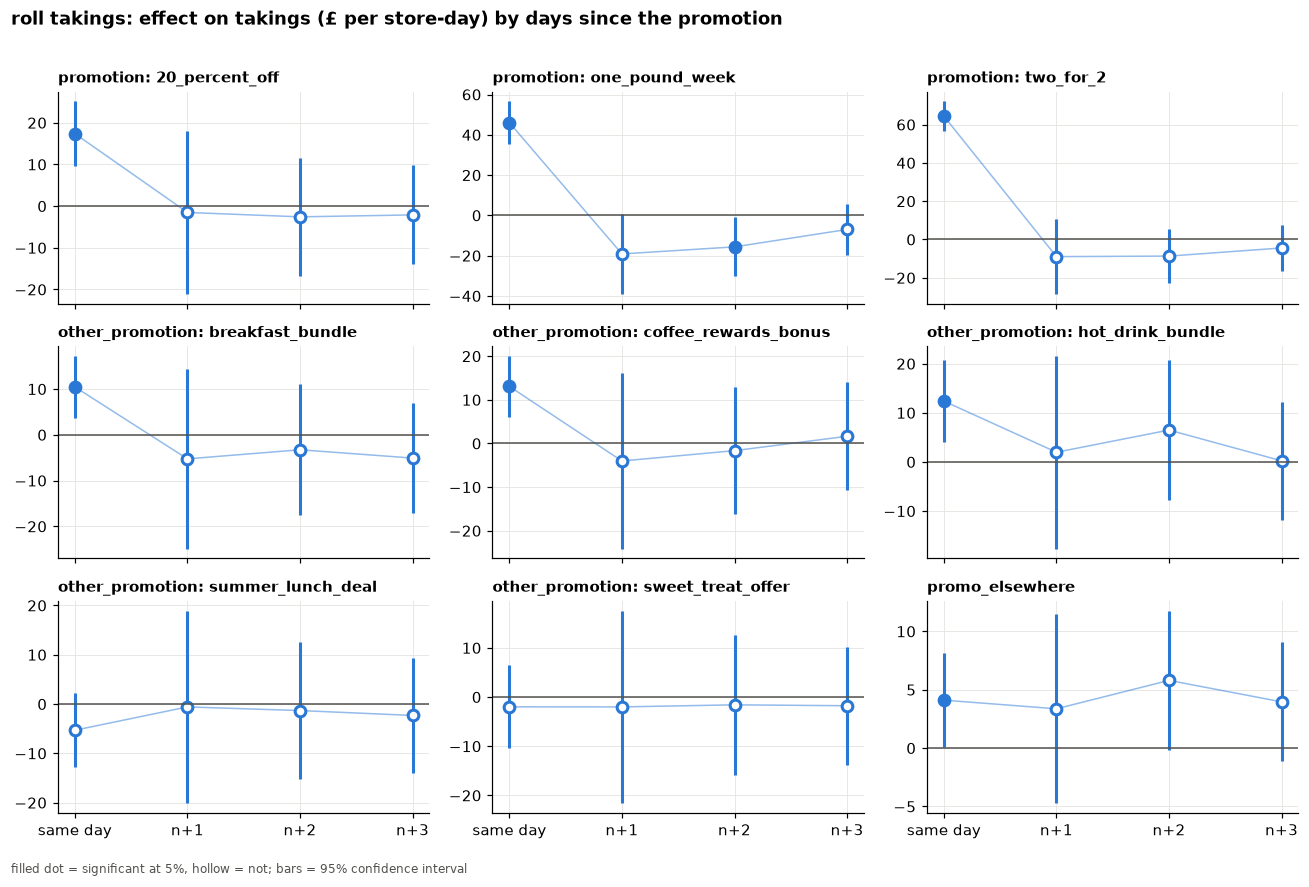

In [6]:
def plot_profile(outcome):
    fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
    for ax, var in zip(axes.flat, order):
        c = coefs[(coefs.outcome == outcome) & (coefs.variable == var)].sort_values("k")
        ax.vlines(c.k, c.low, c.high, color=BLUE, lw=2)
        ax.plot(c.k, c.coef, "-", color=BLUE, lw=1, alpha=0.5)
        for _, r in c.iterrows():  # filled dot = significant at 5%, hollow = not
            ax.plot(r.k, r.coef, "o", ms=7, mfc=BLUE if r.p < 0.05 else "white", mec=BLUE, mew=2)
        ax.axhline(0, color="#52514e", lw=1)
        ax.set_title(var)
        ax.set_xticks(list(horizon), list(horizon.values()))
    fig.suptitle(f"{outcome}: effect on takings (£ per store-day) by days since the promotion", x=0.01, ha="left", fontweight="bold")
    fig.text(0.01, 0.0, "filled dot = significant at 5%, hollow = not; bars = 95% confidence interval", fontsize=8, color="#52514e")
    plt.tight_layout(rect=(0, 0.02, 1, 0.97))

plot_profile("roll takings")

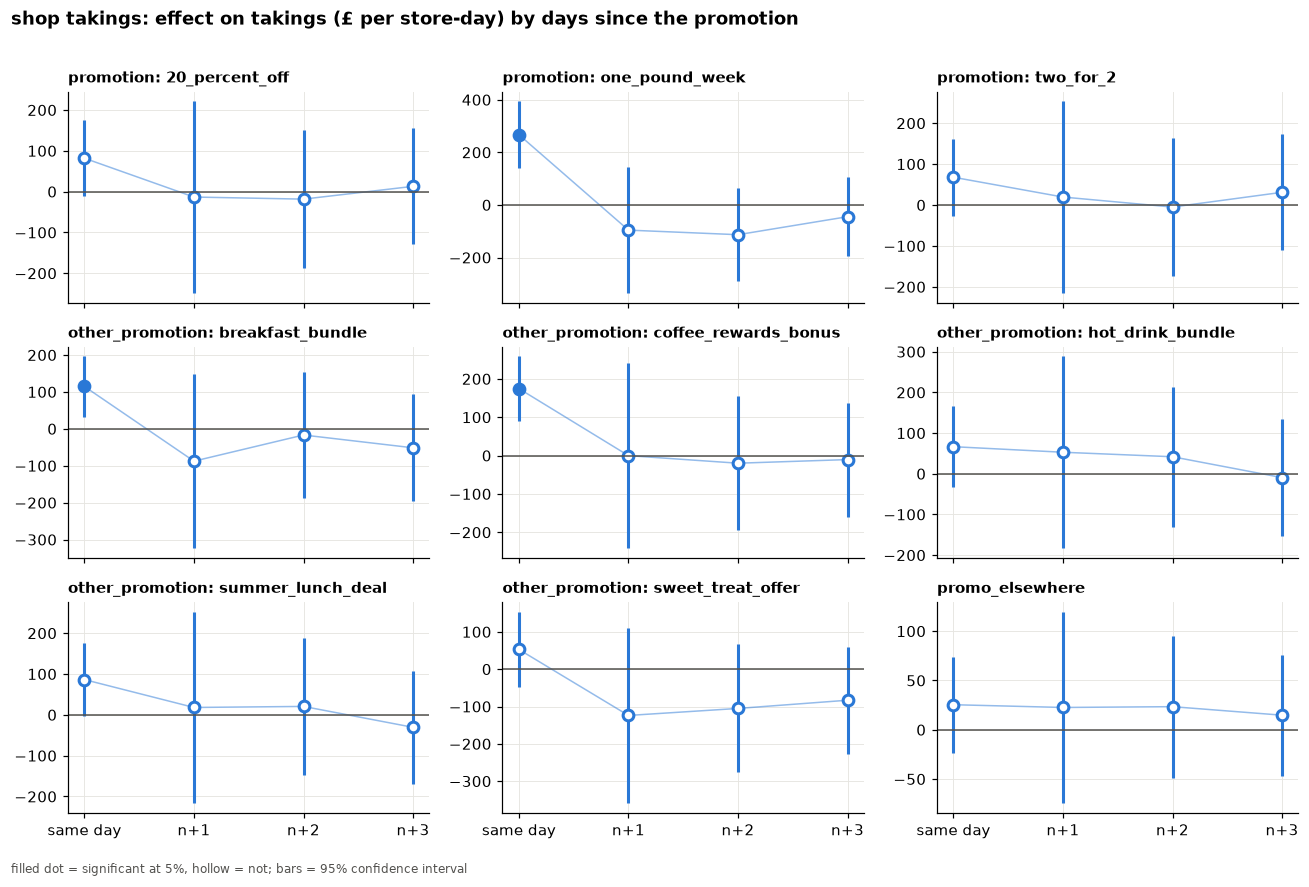

In [7]:
plot_profile("shop takings")

## 5. Why control for what is running on day n+k?

Compare the lag coefficients on `promotion` with and without that control. Without it, the effect looks large and fades slowly,
but that is just the promotion still being on (runs last 1-2 weeks) and then ending.

In [8]:
lag_only = {(name, k): smf.ols(f"{y} ~ {controls} + {earlier}", data=data[k]).fit() for k in (1, 2, 3) for name, y in outcomes.items()}

for name in outcomes:
    cmp = {}
    for k in (1, 2, 3):
        cmp[("lag only (no control)", f"n+{k}")] = lag_only[(name, k)].params.filter(like="C(promotion_lag")
        cmp[("lag + running today (used above)", f"n+{k}")] = fits[(name, k)].params.filter(like="C(promotion_lag")
    cmp = pd.DataFrame(cmp)
    cmp.index = cmp.index.map(label)
    print(name)
    display(cmp)

roll takings


,lag only (no control),lag + running today (used above),lag only (no control),lag + running today (used above),lag only (no control),lag + running today (used above)
,n+1,n+1,n+2,n+2,n+3,n+3
promotion: 20_percent_off,14.847,-1.525,12.576,-2.577,9.967,-2.111
promotion: one_pound_week,33.084,-19.132,23.268,-15.636,19.156,-6.991
promotion: two_for_2,56.968,-8.956,50.479,-8.676,45.144,-4.433


shop takings


,lag only (no control),lag + running today (used above),lag only (no control),lag + running today (used above),lag only (no control),lag + running today (used above)
,n+1,n+1,n+2,n+2,n+3,n+3
promotion: 20_percent_off,73.352,-13.255,61.127,-18.384,61.028,12.930
promotion: one_pound_week,197.842,-95.877,126.544,-113.269,111.315,-44.747
promotion: two_for_2,63.429,19.491,51.211,-4.979,55.787,31.067


## 6. Robustness check

Days at the same store are correlated (a quiet Tuesday is often followed by a quiet Wednesday), which makes plain p-values too optimistic.
We re-run with standard errors that allow for correlation within a store over up to 7 days (`hac-panel`) and count the terms where the 5% call flips.

In [9]:
flips = []
for (name, k), m in fits.items():
    d = data[k]
    robust = smf.ols(m.model.formula, data=d).fit(
        cov_type="hac-panel", cov_kwds={"groups": d.store_id.astype("category").cat.codes, "maxlags": 7})
    t = pd.DataFrame({"p": m.pvalues, "p_robust": robust.pvalues})
    t = t[t.index.str.contains("promo") & (t.index.str.contains("_lag") == (k > 0))]
    flips.append(t.assign(outcome=name, k=k, flip=(t.p < 0.05) != (t.p_robust < 0.05), variable=t.index.map(label)))
flips = pd.concat(flips, ignore_index=True)

print(f"terms where the 5% call flips with robust errors: {flips.flip.sum()} of {len(flips)}")
flips[flips.flip][["outcome", "k", "variable", "p", "p_robust"]]

terms where the 5% call flips with robust errors: 5 of 72


,outcome,k,variable,p,p_robust
8,roll takings,0,promo_elsewhere,0.046,0.073
15,shop takings,0,other_promotion: summer_lunch_deal,0.060,0.023
19,roll takings,1,promotion: one_pound_week,0.059,0.002
37,roll takings,2,promotion: one_pound_week,0.037,0.069
44,roll takings,2,promo_elsewhere,0.057,0.024


## What I found

**Same day (k = 0).** The effects match 03: on roll takings, `two_for_2` +£64, `one_pound_week` +£46, `20_percent_off` +£17 (all p < 0.001). They differ slightly from 03 because `promo_elsewhere` is now in the model.

**Rolling effects (n+1 to n+3)**
- **No clear lingering boost for any promotion.** Once we control for what is running on the outcome day, none of the lagged coefficients is significantly positive.
- **A mild dip after `one_pound_week` (roll takings).** About -£19 on n+1 (p = 0.059) and -£16 on n+2 (p = 0.037), fading to -£7 by n+3 (not significant). The week-long lift (about +£46 a day for 7 days) is much larger than this dip, so the net effect is still clearly positive. With robust standard errors the n+1 dip is stronger (p = 0.002) and the n+2 dip weaker (p = 0.069), so treat it as likely but modest.
- `two_for_2` shows the same direction but smaller (about -£9, -£9, -£4) and not significant; `20_percent_off` shows nothing (about -£2 throughout).
- **Shop takings:** no significant carry-over anywhere, but the intervals are very wide (several hundred £), so this is "can't tell", not "no effect".
- **`other_promotion`:** nothing significant after the offer ends.

**Promotion at other stores (`promo_elsewhere`)**
- No sign that a promotion at another store pulls customers away: if anything, roll takings are slightly **higher** (about +£4 per store-day on the same day, p = 0.046, and +£3 to +£6 on the following days, not significant). With robust standard errors the same-day estimate is no longer significant (p = 0.073), so this is at most a small positive spill-over.
- No effect on shop takings (+£25, p = 0.30).

**Caveats**
- **Low power.** Each roll promotion ended only three times (once per store), and each `other_promotion` ended at the same moment in all three stores, so there are very few "after" days to learn from. Not significant here does not mean there is no effect; the roll-takings intervals are around ±£15-£20.
- Section 5 shows why the control for "running today" matters: without it, the lag coefficients just re-measure the same-day effect (e.g. `two_for_2` +£57, +£50, +£45).
- 5 of 72 terms change their 5% call with robust standard errors (listed in section 6); none changes the overall picture.
- Same limits as 03: few independent promotion periods, and `other_promotion` can't be fully separated from the calendar.